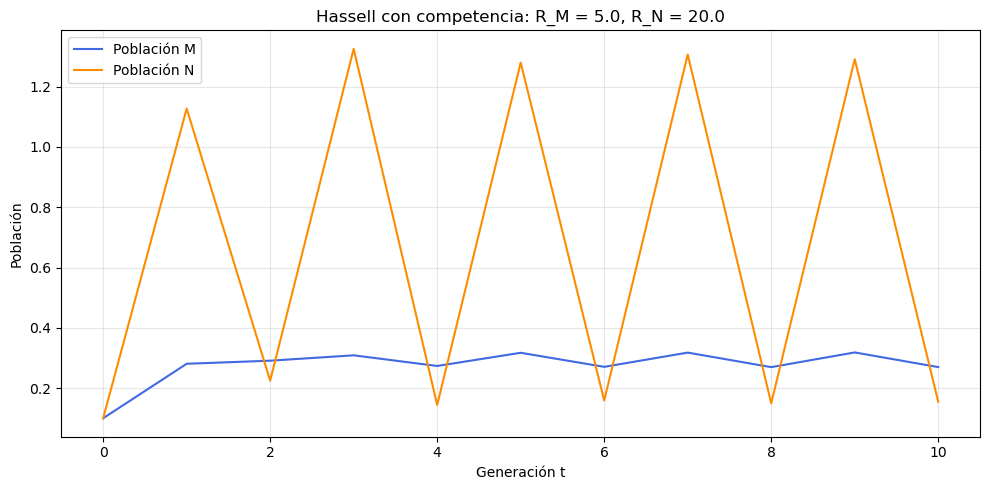

In [54]:
import numpy as np
import matplotlib.pyplot as plt

# Parámetros de Hassell
c_M = 1.0
c_N = 1.0
q_M = 6.0
q_N = 6.0

# Coeficientes de tus términos de competencia
a = 0.05
b = 0.05
c = 0.01
d = 0.01


M0 = 0.1
N0 = 0.1


def hassell(P, R, c, q):
    return R * P / (1 + c * P)**q


def siguiente(M, N, R_M, R_N):
    M_nueva = hassell(M, R_M, c_M, q_M) - a * M * N - c * N
    N_nueva = hassell(N, R_N, c_N, q_N) - b * M * N - d * M

    return M_nueva, N_nueva


R_M = 5.0
R_N = 20.0
generaciones = 10

M = np.zeros(generaciones + 1)
N = np.zeros(generaciones + 1)
M[0], N[0] = M0, N0

for t in range(generaciones):
    M[t + 1], N[t + 1] = siguiente(M[t], N[t], R_M, R_N)

plt.figure(figsize=(10, 5))
plt.plot(M, color="royalblue", label="Población M")
plt.plot(N, color="darkorange", label="Población N")
plt.xlabel("Generación t")
plt.ylabel("Población")
plt.title(f"Hassell con competencia: R_M = {R_M}, R_N = {R_N}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2308\3973271667.py:22: RuntimeWarning: overflow encountered in power
  return R * P / (1 + c * P)**q
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2308\3973271667.py:26: RuntimeWarning: overflow encountered in multiply
  M_nueva = hassell(M, R_M, c_M, q_M) - a * M * N - c * N
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2308\3973271667.py:27: RuntimeWarning: overflow encountered in multiply
  N_nueva = hassell(N, R_N, c_N, q_N) - b * M * N - d * M
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2308\3973271667.py:22: RuntimeWarning: invalid value encountered in divide
  return R * P / (1 + c * P)**q
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2308\3973271667.py:22: RuntimeWarning: overflow encountered in multiply
  return R * P / (1 + c * P)**q


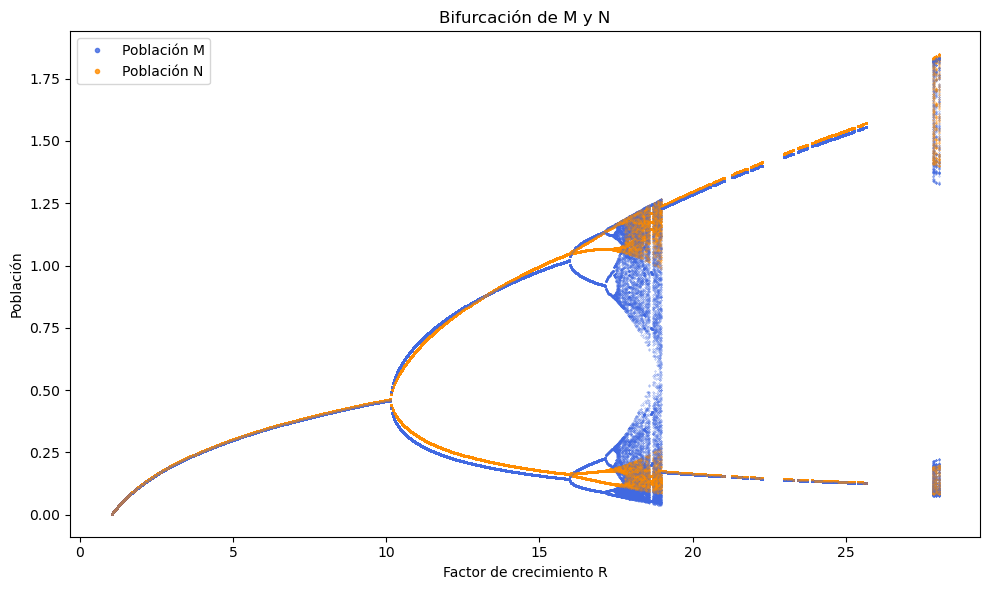

In [ ]:
R_valores = np.linspace(1, 100, 3000)

gamma = 1.0
R_M_valores = R_valores
R_N_valores = gamma * R_valores

M = np.full_like(R_valores, M0)
N = np.full_like(R_valores, N0)

for _ in range(3000):
    M, N = siguiente(M, N, R_M_valores, R_N_valores)

plt.figure(figsize=(10, 6))

for t in range(300):
    M, N = siguiente(M, N, R_M_valores, R_N_valores)

    plt.plot(
        R_valores, M,
        ".", color="royalblue", markersize=0.5, alpha=0.8,
        label="Población M" if t == 0 else None
    )
    plt.plot(
        R_valores, N,
        ".", color="darkorange", markersize=0.5, alpha=0.8,
        label="Población N" if t == 0 else None
    )

plt.xlabel("Factor de crecimiento R")
plt.ylabel("Población")
plt.title(f"Bifurcación de M y N: R_N = {R_N} = R_M")
plt.legend(markerscale=12)
plt.tight_layout()
plt.show()